# Part A

In [1]:
#import library
import numpy as np
import itertools
import matplotlib.pyplot as plt

In [2]:
#define muculloch pitts
class McCulloch_Pitts_neuron():

  def __init__(self , weights , threshold):
    self.weights = weights    #define weights
    self.threshold = threshold    #define threshold

  def model(self , x):
    #define model with threshold
    if np.dot(self.weights ,x) >= self.threshold:
        return 1
    else:
        return 0

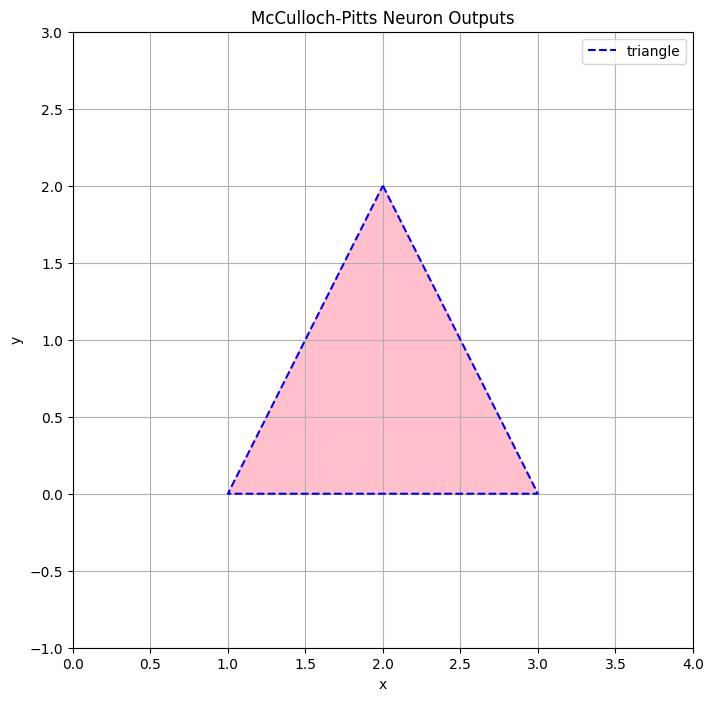

In [57]:
# function to detect the points inside the triangle
def inside_triangle(x, y):


    # AB: 2x + y <= 6 → -2x - y >= -6
    n1 = McCulloch_Pitts_neuron([-2, -1], -6)

    # BC: y >= 0
    n2 = McCulloch_Pitts_neuron([0, 1], 0)

    # CA: y - 2x >= -2 → -2x + y >= -2
    n3 = McCulloch_Pitts_neuron([2, -1], 2)

# Check the output of each neuron
    z1 = n1.model(np.array([x, y]))
    z2 = n2.model(np.array([x, y]))
    z3 = n3.model(np.array([x, y]))

    # فقط اگر همه نورون‌ها فعال باشند → داخل مثلث هست
    out = McCulloch_Pitts_neuron([1, 1, 1], 3)
    return out.model([z1, z2, z3])

# Create a grid of points to display the triangle
x_vals = np.linspace(0, 4,500)
y_vals = np.linspace(-1, 3,500)
X, Y = np.meshgrid(x_vals, y_vals)

# Apply neurons to all points
Z = np.array([[inside_triangle(x, y) for x in x_vals] for y in y_vals])

#plotting triangle
plt.figure(figsize=(8, 8))
plt.contourf(X, Y, Z, levels=[0, 0.5, 1], colors=['white', '#ffc0cb'])

#drawing the outlines
A = [2, 2]
B = [3, 0]
C = [1, 0]
triangle_x = [A[0], B[0], C[0], A[0]]
triangle_y = [A[1], B[1], C[1], A[1]]
plt.plot(triangle_x, triangle_y, color='blue', linestyle='--', label='triangle')

plt.title('McCulloch-Pitts Neuron Outputs')
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(0, 4)
plt.ylim(-1, 3)
plt.grid(True)
plt.legend()
plt.show()

# Part B

In [54]:
#define model for dataset
def Area(x, y):
  neur1 = McCulloch_Pitts_neuron([2, -1], 2)
  neur2 = McCulloch_Pitts_neuron([-2, -1], -6)
  neur3 = McCulloch_Pitts_neuron([0, 1], 0)
  neur4 = McCulloch_Pitts_neuron([1, 1, 1], 3)

  z1 = neur1.model(np.array([x, y]))
  z2 = neur2.model(np.array([x, y]))
  z3 = neur3.model(np.array([x, y]))
  z4 = neur4.model(np.array([z1, z2, z3]))

  # 3 bit output
  # return str(z1) + str(z2)
  return list([z4])

<ipython-input-55-c80840bcf210>:45: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([2, 3], [2, 0], 'k--', label='AB',color='blue')
<ipython-input-55-c80840bcf210>:46: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-." (-> color='k'). The keyword argument will take precedence.
  plt.plot([3, 1], [0, 0], 'k-.', label='BC',color='blue')
<ipython-input-55-c80840bcf210>:47: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k:" (-> color='k'). The keyword argument will take precedence.
  plt.plot([1, 2], [0, 2], 'k:', label='CA',color='blue')


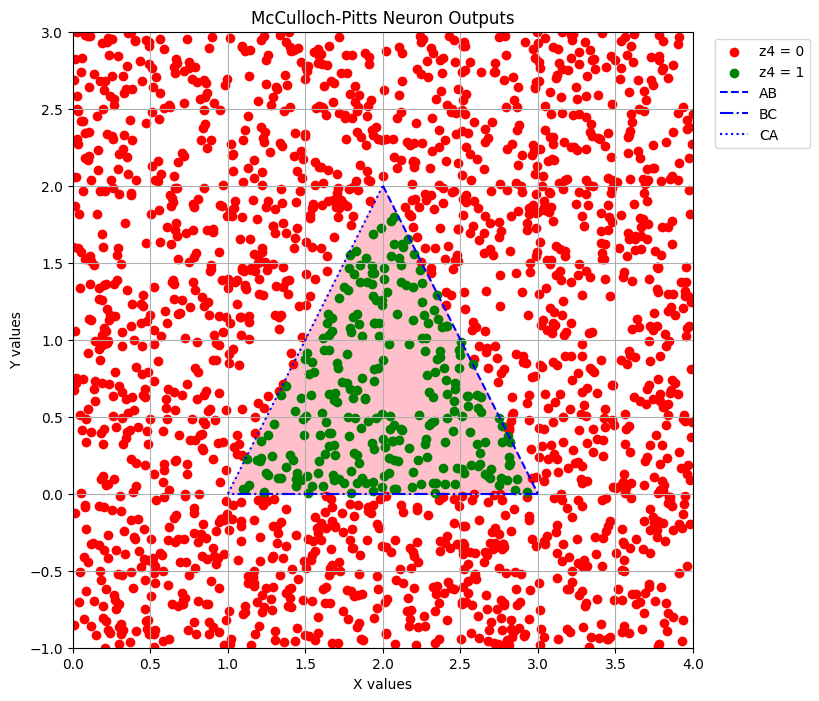

In [55]:

# Generate random data points
num_points = 2000
x_values = np.random.uniform(0, 4, num_points)  # Updated x-axis limits
y_values = np.random.uniform(-1, 3, num_points)  # Updated y-axis limits

# Initialize lists to store data points for different z5 values
red_points = []
green_points = []

# Evaluate data points using the Area function
for i in range(num_points):
    z4_value = Area(x_values[i], y_values[i])
    if z4_value == [0]:  # z5 value is 0
        red_points.append((x_values[i], y_values[i]))
    else:  # z4 value is 1
        green_points.append((x_values[i], y_values[i]))

# Separate x and y values for red and green points
red_x, red_y = zip(*red_points)
green_x, green_y = zip(*green_points)

# Plotting
plt.figure(figsize=(8, 8))

# Create a grid of points to display the triangle
x_vals = np.linspace(0, 4,500)
y_vals = np.linspace(-1, 3,500)
X, Y = np.meshgrid(x_vals, y_vals)

# Apply neurons to all points
Z = np.array([[inside_triangle(x, y) for x in x_vals] for y in y_vals])

# triangle_area
plt.contourf(X, Y, Z, levels=[0, 0.5, 1], colors=['white', '#ffc0cb'])
#dots
plt.scatter(red_x, red_y, color='red', label='z4 = 0')
plt.scatter(green_x, green_y, color='green', label='z4 = 1')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('McCulloch-Pitts Neuron Outputs')



# Plotting lines with legends
plt.plot([2, 3], [2, 0], 'k--', label='AB',color='blue')
plt.plot([3, 1], [0, 0], 'k-.', label='BC',color='blue')
plt.plot([1, 2], [0, 2], 'k:', label='CA',color='blue')

plt.grid(True)

# Set axis limits
plt.xlim(0, 4)
plt.ylim(-1, 3)

# Position the legends at the top and right
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.0))


plt.show()


# Part C

<ipython-input-6-bc7952178c39>:77: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([2, 3], [2, 0], 'k--', label='AB', color='blue')
<ipython-input-6-bc7952178c39>:78: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-." (-> color='k'). The keyword argument will take precedence.
  plt.plot([3, 1], [0, 0], 'k-.', label='BC', color='blue')
<ipython-input-6-bc7952178c39>:79: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k:" (-> color='k'). The keyword argument will take precedence.
  plt.plot([1, 2], [0, 2], 'k:', label='CA', color='blue')


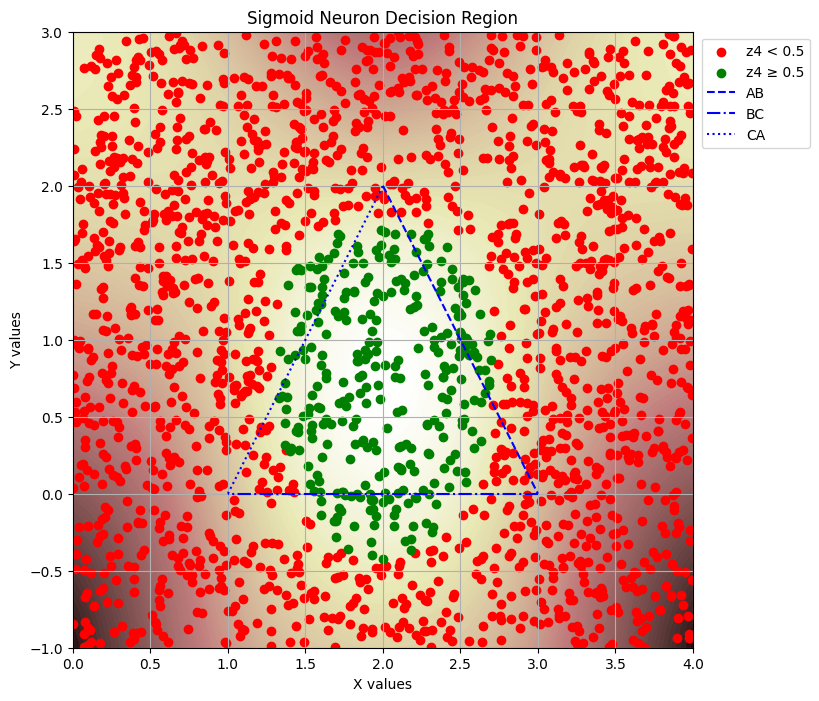

In [6]:

# تابع سیگموید
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# تعریف نورون سیگمویدی
class SigmoidNeuron:
    def __init__(self, weights, bias):
        self.weights = np.array(weights)
        self.bias = bias

    def model(self, x):
        z = np.dot(self.weights, x) + self.bias
        return sigmoid(z)

# تابع Area که تصمیم می‌گیرد نقطه داخل مثلث هست یا نه
def Area(x, y):
    neur1 = SigmoidNeuron([2, -1], -2)     # خط AB
    neur2 = SigmoidNeuron([-2, -1], 6)     # خط BC
    neur3 = SigmoidNeuron([0, 1], 0)       # خط CA
    neur4 = SigmoidNeuron([2, 2, 3.1], -4.9) # نورون جمع‌کننده‌ی نهایی

    z1 = neur1.model(np.array([x, y]))
    z2 = neur2.model(np.array([x, y]))
    z3 = neur3.model(np.array([x, y]))

    z4 = neur4.model(np.array([z1, z2, z3]))

    return z4

# ایجاد نقاط تصادفی
num_points = 2000
x_values = np.random.uniform(0, 4, num_points)
y_values = np.random.uniform(-1, 3, num_points)

# جدا کردن نقاط بر اساس خروجی نورون
red_points = []
green_points = []

for i in range(num_points):
    z4_value = Area(x_values[i], y_values[i])
    if z4_value < 0.5:
        red_points.append((x_values[i], y_values[i]))
    else:
        green_points.append((x_values[i], y_values[i]))

# جدا کردن x و y برای رسم
if red_points:
    red_x, red_y = zip(*red_points)
else:
    red_x, red_y = [], []

if green_points:
    green_x, green_y = zip(*green_points)
else:
    green_x, green_y = [], []

# تولید شبکه برای رسم پس‌زمینه مثلث
x_vals = np.linspace(0, 4, 500)
y_vals = np.linspace(-1, 3, 500)
X, Y = np.meshgrid(x_vals, y_vals)

# محاسبه خروجی نورون روی شبکه
Z = np.array([[Area(x, y) for x in x_vals] for y in y_vals])

# رسم
plt.figure(figsize=(8, 8))

# پس‌زمینه با خروجی نورون
plt.contourf(X, Y, Z, levels=100, cmap='pink')


# نقاط
plt.scatter(red_x, red_y, color='red', label='z4 < 0.5')
plt.scatter(green_x, green_y, color='green', label='z4 ≥ 0.5')

# خطوط مثلث
plt.plot([2, 3], [2, 0], 'k--', label='AB', color='blue')
plt.plot([3, 1], [0, 0], 'k-.', label='BC', color='blue')
plt.plot([1, 2], [0, 2], 'k:', label='CA', color='blue')

# تنظیمات نمودار
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('Sigmoid Neuron Decision Region')
plt.xlim(0, 4)
plt.ylim(-1, 3)
plt.grid(True)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.0))
plt.show()

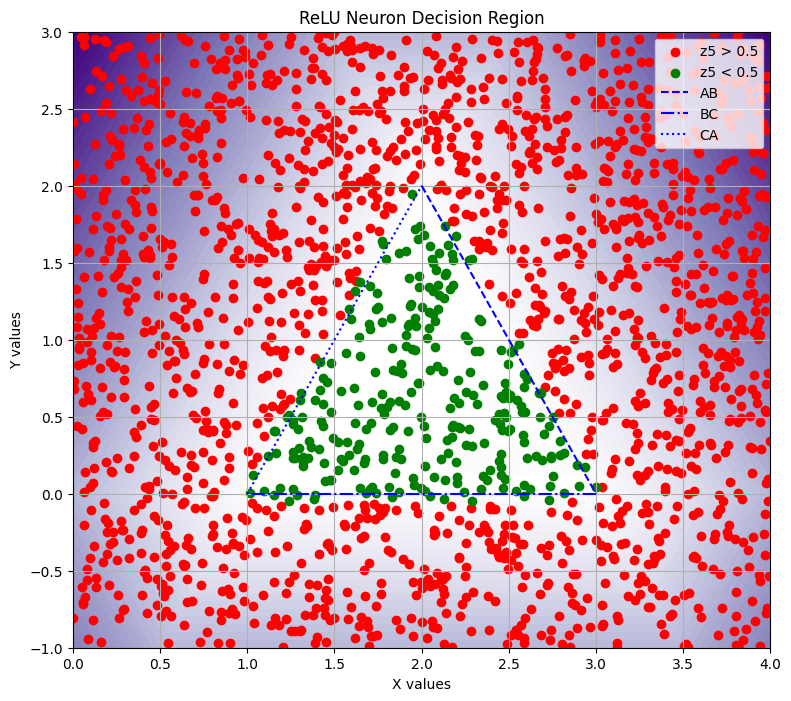

In [61]:

# تابع فعال‌ساز ReLU
def relu(x):
    return np.maximum(0, x)

# نورون با ReLU
class ReLU_Neuron:
    def __init__(self, weights, threshold):
        self.weights = weights
        self.threshold = threshold

    def model(self, x):
        z = np.dot(self.weights, x) - self.threshold
        return relu(z)

# مدل کلی
def Area(x, y):
    neur1 = ReLU_Neuron([2, -1], 2)
    neur2 = ReLU_Neuron([-2, -1], -6)
    neur3 = ReLU_Neuron([0, 1], 0)
    neur4 = ReLU_Neuron([0, 1], 2)
    neur5 = ReLU_Neuron([1, 1, 2], 3.6)  # مقدار آستانه برای ترکیب نهایی

    z1 = neur1.model(np.array([x, y]))
    z2 = neur2.model(np.array([x, y]))
    z3 = neur3.model(np.array([x, y]))
    z4 = neur4.model(np.array([x, y]))
    z5 = neur5.model(np.array([z1, z2, z3]))

    return z5

# تولید داده تصادفی
num_points = 2000
x_values = np.random.uniform(0, 4, num_points)
y_values = np.random.uniform(-1, 3, num_points)

# دسته‌بندی نقاط
red_points = []
green_points = []

for i in range(num_points):
    z5_value = Area(x_values[i], y_values[i])
    if z5_value > 0.5:
        red_points.append((x_values[i], y_values[i]))
    else:
        green_points.append((x_values[i], y_values[i]))

# جدا کردن مختصات X و Y
if red_points:
    red_x, red_y = zip(*red_points)
else:
    red_x, red_y = [], []

if green_points:
    green_x, green_y = zip(*green_points)
else:
    green_x, green_y = [], []

# رسم منطقه تصمیم
plt.figure(figsize=(9, 8))
x_vals = np.linspace(0, 4, 500)
y_vals = np.linspace(-1, 3, 500)
X, Y = np.meshgrid(x_vals, y_vals)
Z = np.array([[Area(x, y) for x in x_vals] for y in y_vals])

plt.contourf(X, Y, Z, levels=50, cmap='Purples')  # نمایش شدت خروجی ReLU

# نقاط قرمز و سبز
plt.scatter(red_x, red_y, color='red', label='z5 > 0.5')
plt.scatter(green_x, green_y, color='green', label='z5 < 0.5')

# مثلث
plt.plot([2, 3], [2, 0], 'b--', label='AB')
plt.plot([3, 1], [0, 0], 'b-.', label='BC')
plt.plot([1, 2], [0, 2], 'b:', label='CA')

# تنظیمات نمودار
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('ReLU Neuron Decision Region')
plt.grid(True)
plt.legend(loc='upper right')
plt.xlim(0, 4)
plt.ylim(-1, 3)
plt.show()